# 04 — Dynamic Panels: The LSDVC Estimator

**Duration:** ~60 minutes  
**Level:** Intermediate  
**Prerequisites:** Fixed Effects (02), basic knowledge of dynamic panels

## Learning Objectives

By the end of this notebook, you will be able to:
1. Understand why Fixed Effects is biased with lagged dependent variables (Nickell bias)
2. Apply the LSDVC estimator to correct this bias
3. Compare different initial estimators and bias correction orders
4. Use bootstrap inference for hypothesis testing
5. Apply LSDVC to a credit risk panel dataset

## Outline
1. [Motivation: The Nickell Bias](#part1)
2. [The LSDVC Estimator](#part2)
3. [Sensitivity Analysis](#part3)
4. [Monte Carlo Simulation](#part4)
5. [Application: Credit Risk](#part5)

In [1]:
# Setup
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add project root to path
project_root = Path("../../..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from panelbox.models.dynamic.lsdvc import LSDVC
from panelbox.models.static.fixed_effects import FixedEffects
from panelbox.datasets.load import load_grunfeld, load_abdata

# Plot style
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(42)
print("Setup complete.")

Setup complete.


---
<a id="part1"></a>
# Part 1: Motivation — The Nickell Bias

## The Dynamic Panel Model

Many economic variables are **persistent**: today's value depends on yesterday's. The canonical dynamic panel model is:

$$y_{it} = \rho \, y_{i,t-1} + \beta' X_{it} + \alpha_i + \varepsilon_{it}$$

where $|\rho| < 1$ ensures stationarity and $\alpha_i$ captures unobserved heterogeneity.

## The Problem

Fixed Effects (Within) estimation **demeans** the data to eliminate $\alpha_i$. But the demeaned lag $\tilde{y}_{i,t-1}$ is mechanically correlated with the demeaned error $\tilde{\varepsilon}_{it}$ because $\bar{y}_i$ contains $\varepsilon_{it}$ and $\bar{\varepsilon}_i$ contains $y_{i,t-1}$.

**Nickell (1981)** showed the FE estimator is biased:

$$\text{plim}_{N \to \infty} \hat{\rho}_{FE} \approx \rho - \frac{1 + \rho}{T - 1}$$

This bias is **negative** and substantial for small $T$.

### Simulation: FE bias as a function of T

Let's simulate AR(1) panels with $\rho = 0.5$ and see how bad FE bias gets.

In [2]:
# Simulate AR(1) panel data
def simulate_ar1_panel(N, T, rho, sigma_alpha=1.0, sigma_eps=1.0, seed=None):
    """Generate balanced AR(1) panel: y_it = rho * y_{i,t-1} + alpha_i + eps_it."""
    rng = np.random.default_rng(seed)
    alpha = rng.normal(0, sigma_alpha, N)
    
    # Start from stationary distribution
    y = np.zeros((N, T + 1))
    y[:, 0] = alpha / (1 - rho) + rng.normal(0, sigma_eps / np.sqrt(1 - rho**2), N)
    
    for t in range(1, T + 1):
        y[:, t] = rho * y[:, t - 1] + alpha + rng.normal(0, sigma_eps, N)
    
    # Build DataFrame (drop the burn-in period 0)
    rows = []
    for i in range(N):
        for t in range(1, T + 1):
            rows.append({"entity": i, "time": t, "y": y[i, t], "y_lag": y[i, t - 1]})
    return pd.DataFrame(rows)

# FE estimator (within)
def fe_rho(df):
    """Quick within-estimator of rho."""
    means = df.groupby("entity")[["y", "y_lag"]].transform("mean")
    y_w = df["y"] - means["y"]
    x_w = df["y_lag"] - means["y_lag"]
    return (x_w * y_w).sum() / (x_w ** 2).sum()

# Simulate across different T values
true_rho = 0.5
N = 100
T_values = [5, 7, 10, 15, 20, 30, 50]
n_mc = 200

fe_biases = []
for T in T_values:
    rho_hats = []
    for rep in range(n_mc):
        df = simulate_ar1_panel(N, T, true_rho, seed=rep * 1000 + T)
        rho_hats.append(fe_rho(df))
    fe_biases.append(np.mean(rho_hats) - true_rho)
    
# Theoretical Nickell bias
nickell_bias = [-(1 + true_rho) / (T - 1) for T in T_values]

print("T  | FE Bias (simulated) | Nickell formula")
print("---|---------------------|----------------")
for T, sim, theory in zip(T_values, fe_biases, nickell_bias):
    print(f"{T:>2} | {sim:>19.4f} | {theory:>14.4f}")

T  | FE Bias (simulated) | Nickell formula
---|---------------------|----------------
 5 |             -0.3316 |        -0.3750
 7 |             -0.2314 |        -0.2500
10 |             -0.1630 |        -0.1667
15 |             -0.1063 |        -0.1071
20 |             -0.0805 |        -0.0789
30 |             -0.0511 |        -0.0517
50 |             -0.0316 |        -0.0306


<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2006084/1839032216.py:7: SyntaxWarning: invalid escape sequence '\h'
  ax.set_ylabel(f"Bias ($\hat{{\\rho}}_{{FE}} - \\rho$)")


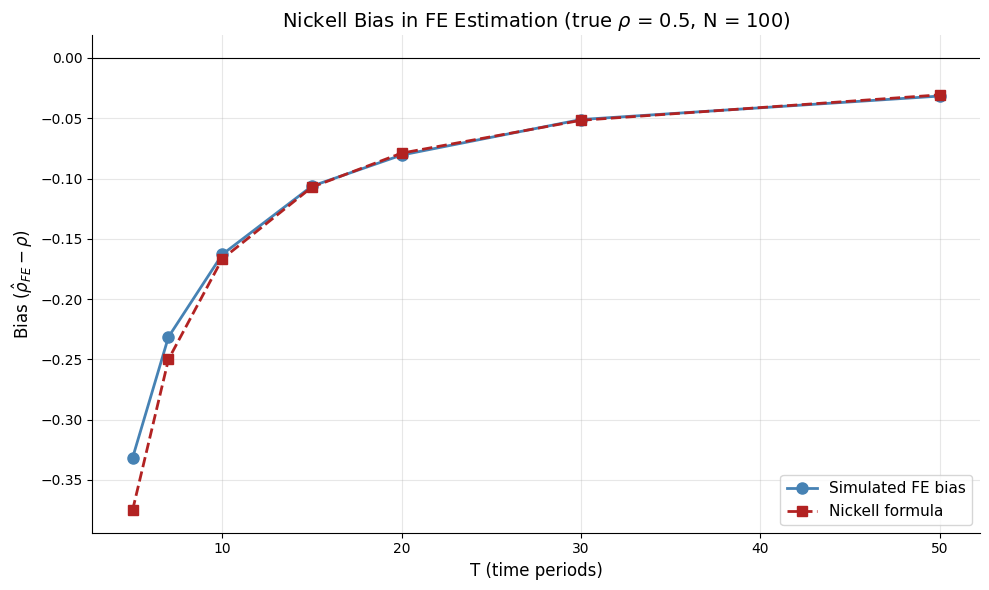


With T=5, FE underestimates rho by ~0.33 (true rho = 0.5)
With T=50, the bias shrinks to ~0.032


In [3]:
# Plot: Nickell bias as function of T
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(T_values, fe_biases, "o-", color="steelblue", linewidth=2, markersize=8, label="Simulated FE bias")
ax.plot(T_values, nickell_bias, "s--", color="firebrick", linewidth=2, markersize=7, label="Nickell formula")
ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
ax.set_xlabel("T (time periods)")
ax.set_ylabel(f"Bias ($\hat{{\\rho}}_{{FE}} - \\rho$)")
ax.set_title(f"Nickell Bias in FE Estimation (true $\\rho$ = {true_rho}, N = {N})")
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"\nWith T=5, FE underestimates rho by ~{abs(fe_biases[0]):.2f} (true rho = {true_rho})")
print(f"With T=50, the bias shrinks to ~{abs(fe_biases[-1]):.3f}")

### Intuition: Why does the bias arise?

The Within transformation subtracts entity means:

$$\tilde{y}_{it} = y_{it} - \bar{y}_i, \quad \tilde{y}_{i,t-1} = y_{i,t-1} - \bar{y}_i$$

The problem: $\bar{y}_i = \frac{1}{T}\sum_t y_{it}$ **includes** $y_{it}$, which depends on $\varepsilon_{it}$.  
Meanwhile, $\bar{\varepsilon}_i$ is part of $\tilde{\varepsilon}_{it}$ and also appears (via the model) in future $y$'s.

So $\tilde{y}_{i,t-1}$ and $\tilde{\varepsilon}_{it}$ share terms through the entity mean — they are **correlated by construction**.

This correlation is of order $O(1/T)$: with large $T$ it vanishes, but for typical micro-panels ($T = 5$-$20$), the bias is severe.

---
<a id="part2"></a>
# Part 2: The LSDVC Estimator

## Algorithm Overview

**Kiviet (1995)** derived an analytical formula for the FE bias in dynamic panels. The LSDVC uses this to *correct* the FE (LSDV) estimator:

**Step 1: LSDV Estimation**  
Run Fixed Effects on $(y_{it}, y_{i,t-1}, X_{it})$ to get $\hat{\rho}_{LSDV}$ and $\hat{\sigma}^2$.

**Step 2: Initial Consistent Estimate**  
Get a consistent (but inefficient) estimate of $\rho$ using one of:
- **Anderson-Hsiao (AH)**: IV with lagged differences or levels as instruments
- **Arellano-Bond (AB)**: Difference GMM (recommended)
- **Blundell-Bond (BB)**: System GMM

**Step 3: Bias Correction**  
Use the initial $\hat{\rho}$ to compute the analytical bias via Kiviet's formula, then iterate:
1. Compute bias $B(\hat{\rho})$ using the formula
2. Correct: $\hat{\rho}_{new} = \hat{\rho}_{LSDV} - B(\hat{\rho})$
3. Repeat until convergence

**Step 4: Bootstrap Inference**  
Standard errors come from parametric bootstrap: simulate data from the estimated DGP, re-estimate LSDVC, and build the sampling distribution.

### Basic Example with Grunfeld Data

In [4]:
# Load Grunfeld investment data
data = load_grunfeld()
print(f"Grunfeld data: {data.shape[0]} obs, {data['firm'].nunique()} firms, {data['year'].nunique()} years")
print(f"Variables: {data.columns.tolist()}")
data.head()

Grunfeld data: 200 obs, 10 firms, 20 years
Variables: ['firm', 'year', 'invest', 'value', 'capital']


,firm,year,invest,value,capital
0,1,1935,317.6,3078.5,2.8
1,1,1936,391.8,4661.7,52.6
2,1,1937,410.6,5387.1,156.9
3,1,1938,257.7,2792.2,209.2
4,1,1939,330.8,4313.2,203.4


In [5]:
# FE estimation with manual lag (for comparison)
data_sorted = data.sort_values(["firm", "year"]).copy()
data_sorted["invest_lag"] = data_sorted.groupby("firm")["invest"].shift(1)
data_fe = data_sorted.dropna(subset=["invest_lag"]).copy()

fe = FixedEffects("invest ~ invest_lag + value + capital", data_fe, "firm", "year")
res_fe = fe.fit(cov_type="clustered")

print("=== Fixed Effects (biased with lagged dependent variable) ===")
print(res_fe.summary())

=== Fixed Effects (biased with lagged dependent variable) ===
                       Fixed Effects Estimation Results                       
Formula: invest ~ invest_lag + value + capital
Model:   Fixed Effects
------------------------------------------------------------------------------
No. Observations:                 190
No. Entities:                      10
No. Time Periods:                  19
Degrees of Freedom:               177
R-squared:                     0.8767
Adj. R-squared:                0.8684
R-squared (within):            0.8767
R-squared (between):           1.0000
R-squared (overall):           0.9718
Standard Errors:            clustered
F-statistic (FE vs OLS):      14.0525
F-test p-value:                0.0000
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
invest_lag           0.6229      0.1111   5.606  0.0000    0.4036    0.8421 ***
value        

In [6]:
# LSDVC estimation — the lag is added automatically
lsdvc = LSDVC("invest ~ value + capital", data, "firm", "year",
              initial_estimator='ab', bias_order=2)

res_lsdvc = lsdvc.fit(n_bootstrap=500, seed=42)

print("=== LSDVC (bias-corrected) ===")
print(res_lsdvc.summary())

=== LSDVC (bias-corrected) ===
                           LSDVC Estimation Results                           
Formula: invest ~ value + capital
Model:   LSDVC
Initial Estimator:                 AB
Bias Correction Order:              2
Convergence:                      Yes (6 iterations)
------------------------------------------------------------------------------
No. Observations:                 190
No. Entities:                      10
No. Time Periods:                  19
Sigma^2:                    1453.7587
Standard Errors:            bootstrap
Bootstrap Replications:           500
Variable        Coef.        Std.Err.     z        P>|z|    [0.025     0.975]    
------------------------------------------------------------------------------
L1.invest            0.7103      0.0536  13.253  0.0000    0.6015    0.8196 ***
value                0.1015      0.0090  11.254  0.0000    0.0857    0.1209 ***
capital              0.1526      0.0227   6.718  0.0000    0.1367    0.2217 ***
Sign

In [7]:
# Comparison table: FE vs LSDVC
print("=" * 65)
print("         FE vs LSDVC: Coefficient Comparison")
print("=" * 65)
print(f"{'Variable':<15} {'FE':>12} {'LSDVC':>12} {'Difference':>12}")
print("-" * 65)

# Map FE param names to LSDVC names
fe_map = {"invest_lag": "L1.invest", "value": "value", "capital": "capital"}
for fe_name, lsdvc_name in fe_map.items():
    fe_val = res_fe.params[fe_name]
    lsdvc_val = res_lsdvc.params[lsdvc_name]
    diff = lsdvc_val - fe_val
    print(f"{lsdvc_name:<15} {fe_val:>12.4f} {lsdvc_val:>12.4f} {diff:>12.4f}")
print("=" * 65)
print(f"\nThe lagged dependent variable coefficient increases from {res_fe.params['invest_lag']:.4f}")
print(f"to {res_lsdvc.params['L1.invest']:.4f} after bias correction (+{res_lsdvc.params['L1.invest'] - res_fe.params['invest_lag']:.4f}).")
print("This is consistent with FE having a downward bias (Nickell).")

         FE vs LSDVC: Coefficient Comparison
Variable                  FE        LSDVC   Difference
-----------------------------------------------------------------
L1.invest             0.6229       0.7103       0.0874
value                 0.1015       0.1015       0.0000
capital               0.1526       0.1526       0.0000

The lagged dependent variable coefficient increases from 0.6229
to 0.7103 after bias correction (+0.0874).
This is consistent with FE having a downward bias (Nickell).


In [8]:
# Bias correction detail
print(res_lsdvc.bias_summary())

                LSDVC Bias Correction Detail                
Variable        LSDV         LSDVC        Correction  
------------------------------------------------------------
L1.invest            0.6229      0.7103     -0.0874
value                0.1015      0.1015      0.0000
capital              0.1526      0.1526      0.0000
------------------------------------------------------------
Initial estimator: AB
Initial rho:       0.313669
Bias order:        2
Iterations:        6
Converged:         True


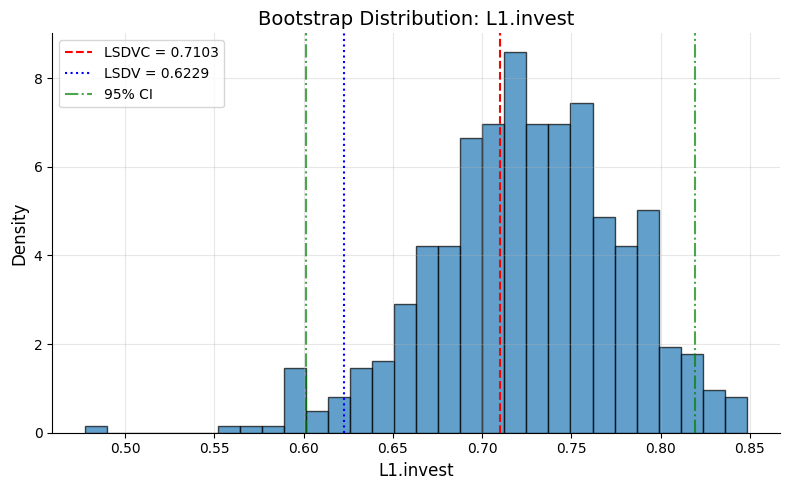

In [9]:
# Bootstrap distribution of rho
fig = res_lsdvc.plot_bootstrap_distribution(variable="L1.invest")
plt.show()

---
<a id="part3"></a>
# Part 3: Sensitivity Analysis

### Comparing Initial Estimators (AH, AB, BB)

The LSDVC uses an initial consistent estimate of $\rho$ as a starting point for bias correction. In theory, the corrected estimate should be robust to this choice (the iteration converges). Let's verify.

In [10]:
# Compare initial estimators
results_by_init = {}
for est in ["ah", "ab", "bb"]:
    model = LSDVC("invest ~ value + capital", data, "firm", "year",
                  initial_estimator=est, bias_order=2)
    res = model.fit(n_bootstrap=200, seed=42)
    results_by_init[est] = res

print("=" * 70)
print("       Sensitivity to Initial Estimator")
print("=" * 70)
print(f"{'Estimator':<12} {'Init. rho':>10} {'LSDVC rho':>12} {'SE(rho)':>10} {'Iters':>6}")
print("-" * 70)
for est, res in results_by_init.items():
    print(f"{est.upper():<12} {res.initial_rho:>10.4f} {res.params['L1.invest']:>12.4f} "
          f"{res.std_errors['L1.invest']:>10.4f} {res.n_iterations:>6}")
print("=" * 70)
print("\nAll three converge to very similar LSDVC estimates, as expected.")
print("BB starts closest to the final value, so it converges fastest.")

       Sensitivity to Initial Estimator
Estimator     Init. rho    LSDVC rho    SE(rho)  Iters
----------------------------------------------------------------------
AH               0.1875       0.7103     0.0512      6
AB               0.3137       0.7103     0.0512      6
BB               0.7119       0.7103     0.0512      4

All three converge to very similar LSDVC estimates, as expected.
BB starts closest to the final value, so it converges fastest.


### Comparing Bias Correction Orders (1, 2, 3)

Kiviet's bias formula has multiple terms. Higher orders provide more accurate corrections but may be noisier in small samples.

In [11]:
# Compare bias orders
results_by_order = {}
for order in [1, 2, 3]:
    model = LSDVC("invest ~ value + capital", data, "firm", "year",
                  initial_estimator="ab", bias_order=order)
    res = model.fit(n_bootstrap=200, seed=42)
    results_by_order[order] = res

print("=" * 60)
print("    Sensitivity to Bias Correction Order")
print("=" * 60)
print(f"{'Order':<8} {'LSDVC rho':>12} {'SE(rho)':>10} {'Iters':>6}")
print("-" * 60)
for order, res in results_by_order.items():
    print(f"{order:<8} {res.params['L1.invest']:>12.4f} "
          f"{res.std_errors['L1.invest']:>10.4f} {res.n_iterations:>6}")
print("-" * 60)
print(f"{'LSDV':<8} {res.lsdv_params['L1.invest']:>12.4f}")
print("=" * 60)
print("\nOrder 2 is the recommended default (Kiviet, 1995).")
print("The differences between orders are small with T=19.")

    Sensitivity to Bias Correction Order
Order       LSDVC rho    SE(rho)  Iters
------------------------------------------------------------
1              0.7183     0.0510      6
2              0.7103     0.0512      6
3              0.7096     0.0509      6
------------------------------------------------------------
LSDV           0.6229

Order 2 is the recommended default (Kiviet, 1995).
The differences between orders are small with T=19.


### Effect of Bootstrap Replications on Standard Errors

More bootstrap replicas give more stable SE estimates, but at a computational cost.

In [12]:
# Bootstrap SE stability
boot_sizes = [50, 100, 200, 500, 1000]
se_results = []

for B in boot_sizes:
    model = LSDVC("invest ~ value + capital", data, "firm", "year",
                  initial_estimator="ab", bias_order=2)
    res = model.fit(n_bootstrap=B, seed=42)
    se_results.append(res.std_errors["L1.invest"])

print("=" * 45)
print("  Bootstrap Replications vs SE(rho)")
print("=" * 45)
print(f"{'B':>8} {'SE(rho)':>12}")
print("-" * 45)
for B, se in zip(boot_sizes, se_results):
    print(f"{B:>8} {se:>12.4f}")
print("=" * 45)
print("\nSE stabilizes around B=200-500.")
print("B=500 is a good default for most applications.")

  Bootstrap Replications vs SE(rho)
       B      SE(rho)
---------------------------------------------
      50       0.0565
     100       0.0522
     200       0.0512
     500       0.0536
    1000       0.0532

SE stabilizes around B=200-500.
B=500 is a good default for most applications.


---
<a id="part4"></a>
# Part 4: Monte Carlo Simulation

Let's run a small Monte Carlo to compare the **distribution** of FE vs LSDVC estimators with a known DGP.

In [13]:
# Monte Carlo: FE vs LSDVC
true_rho = 0.5
N_mc, T_mc = 50, 10
n_replicas = 100

rho_fe_list = []
rho_lsdvc_list = []

print(f"Running Monte Carlo: {n_replicas} replications, N={N_mc}, T={T_mc}, rho={true_rho}")
print("This may take a few minutes...")

for rep in range(n_replicas):
    # Simulate AR(1) panel
    df_mc = simulate_ar1_panel(N_mc, T_mc, true_rho, seed=rep)
    
    # FE estimate
    rho_fe_list.append(fe_rho(df_mc))
    
    # LSDVC estimate (no bootstrap for speed)
    try:
        df_mc_renamed = df_mc.rename(columns={"entity": "ent", "time": "t"})
        # Need an exogenous variable for LSDVC (use constant via a dummy)
        df_mc_renamed["x"] = np.random.default_rng(rep).normal(0, 1, len(df_mc_renamed))
        model = LSDVC("y ~ x", df_mc_renamed, "ent", "t",
                      initial_estimator="ab", bias_order=2)
        res = model.fit(n_bootstrap=0)
        rho_lsdvc_list.append(res.params["L1.y"])
    except Exception:
        rho_lsdvc_list.append(np.nan)
    
    if (rep + 1) % 25 == 0:
        print(f"  ... completed {rep + 1}/{n_replicas}")

rho_fe = np.array(rho_fe_list)
rho_lsdvc = np.array([x for x in rho_lsdvc_list if not np.isnan(x)])
print(f"\nCompleted. Valid LSDVC estimates: {len(rho_lsdvc)}/{n_replicas}")

Running Monte Carlo: 100 replications, N=50, T=10, rho=0.5
This may take a few minutes...


  ... completed 25/100


  ... completed 50/100


  ... completed 75/100


  ... completed 100/100

Completed. Valid LSDVC estimates: 100/100


<>:9: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2006084/521900652.py:9: SyntaxWarning: invalid escape sequence '\h'
  ax.set_xlabel("$\hat{\\rho}$")


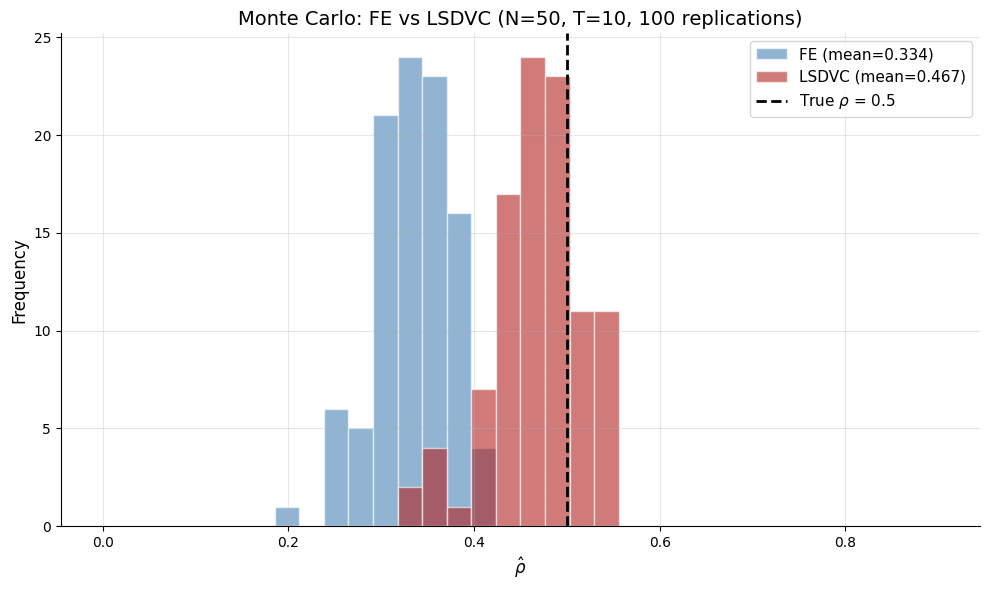

In [14]:
# Histogram: FE vs LSDVC
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0.0, 0.9, 35)
ax.hist(rho_fe, bins=bins, alpha=0.6, label=f"FE (mean={np.mean(rho_fe):.3f})", 
        color="steelblue", edgecolor="white")
ax.hist(rho_lsdvc, bins=bins, alpha=0.6, label=f"LSDVC (mean={np.nanmean(rho_lsdvc):.3f})", 
        color="firebrick", edgecolor="white")
ax.axvline(true_rho, color="black", linewidth=2, linestyle="--", label=f"True $\\rho$ = {true_rho}")
ax.set_xlabel("$\hat{\\rho}$")
ax.set_ylabel("Frequency")
ax.set_title(f"Monte Carlo: FE vs LSDVC (N={N_mc}, T={T_mc}, {n_replicas} replications)")
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [15]:
# Summary statistics
def coverage_95(estimates, true_val):
    """Fraction of estimates whose 95% normal CI covers the true value."""
    se = np.std(estimates)
    lower = estimates - 1.96 * se
    upper = estimates + 1.96 * se
    return np.mean((lower <= true_val) & (true_val <= upper))

print("=" * 60)
print("       Monte Carlo Results: FE vs LSDVC")
print(f"       (N={N_mc}, T={T_mc}, rho={true_rho}, MC={n_replicas})")
print("=" * 60)
print(f"{'Metric':<20} {'FE':>15} {'LSDVC':>15}")
print("-" * 60)
print(f"{'Mean':.<20} {np.mean(rho_fe):>15.4f} {np.nanmean(rho_lsdvc):>15.4f}")
print(f"{'Bias':.<20} {np.mean(rho_fe) - true_rho:>15.4f} {np.nanmean(rho_lsdvc) - true_rho:>15.4f}")
print(f"{'Std. Dev.':.<20} {np.std(rho_fe):>15.4f} {np.nanstd(rho_lsdvc):>15.4f}")
rmse_fe = np.sqrt(np.mean((rho_fe - true_rho)**2))
rmse_lsdvc = np.sqrt(np.nanmean((rho_lsdvc - true_rho)**2))
print(f"{'RMSE':.<20} {rmse_fe:>15.4f} {rmse_lsdvc:>15.4f}")
print(f"{'95% Coverage':.<20} {coverage_95(rho_fe, true_rho):>15.1%} {coverage_95(rho_lsdvc, true_rho):>15.1%}")
print("=" * 60)
print("\nLSDVC substantially reduces the bias compared to FE.")

       Monte Carlo Results: FE vs LSDVC
       (N=50, T=10, rho=0.5, MC=100)
Metric                            FE           LSDVC
------------------------------------------------------------
Mean................          0.3342          0.4674
Bias................         -0.1658         -0.0326
Std. Dev............          0.0410          0.0488
RMSE................          0.1708          0.0587
95% Coverage........            0.0%           89.0%

LSDVC substantially reduces the bias compared to FE.


---
<a id="part5"></a>
# Part 5: Application — Credit Risk

## Default Rates and Persistence

In credit risk, **default rates** (or transition rates to default, TAP) exhibit strong **temporal persistence**: a pool with high defaults this year tends to have high defaults next year. This persistence reflects:

- **Macro cycles**: economic conditions affect all borrowers in a pool
- **Composition effects**: pool quality evolves slowly
- **Contagion**: defaults in a pool can trigger further defaults

The dynamic panel model captures this:

$$\text{tap}_{pt} = \rho \cdot \text{tap}_{p,t-1} + \beta' X_{pt} + \alpha_p + \varepsilon_{pt}$$

where $p$ indexes credit pools and $\alpha_p$ captures unobserved pool-level risk characteristics.

**Why LSDVC?** Credit risk panels typically have:
- Small $T$ (5-15 years of data)
- Moderate $N$ (10-50 pools)
- Strong persistence ($\rho > 0.5$)

This is exactly the regime where Nickell bias is severe and LSDVC shines.

In [16]:
# Simulate credit risk panel data
def simulate_credit_panel(N_pools=20, T_years=10, rho=0.6, seed=42):
    """
    Simulate credit pool panel data.
    
    DGP: tap_pt = rho * tap_{p,t-1} + beta1 * gdp_growth_t + beta2 * pool_size_pt + alpha_p + eps
    """
    rng = np.random.default_rng(seed)
    
    # True parameters
    beta_gdp = -0.02      # Higher GDP growth -> lower default rate
    beta_size = -0.001     # Larger pools -> slightly lower default rate (diversification)
    sigma_alpha = 0.02     # Pool fixed effect std
    sigma_eps = 0.01       # Idiosyncratic shock std
    
    # Pool fixed effects (some pools are riskier)
    alpha = rng.normal(0, sigma_alpha, N_pools)
    
    # Common macro factor (GDP growth)
    gdp_growth = rng.normal(0.02, 0.015, T_years + 1)  # mean 2%, std 1.5%
    gdp_growth = np.clip(gdp_growth, -0.05, 0.08)
    
    rows = []
    # Initialize TAP from stationary distribution
    tap_prev = np.abs(alpha / (1 - rho) + rng.normal(0.05, sigma_eps / np.sqrt(1 - rho**2), N_pools))
    
    for t in range(T_years + 1):
        pool_sizes = rng.uniform(100, 10000, N_pools)
        eps = rng.normal(0, sigma_eps, N_pools)
        
        if t == 0:
            tap = tap_prev
        else:
            tap = rho * tap_prev + beta_gdp * gdp_growth[t] + beta_size * np.log(pool_sizes) + alpha + eps
            tap = np.clip(tap, 0.001, 0.5)  # Keep TAP in reasonable range
        
        for p in range(N_pools):
            rows.append({
                "pool": f"P{p+1:02d}",
                "year": 2010 + t,
                "tap": tap[p],
                "gdp_growth": gdp_growth[t],
                "log_pool_size": np.log(pool_sizes[p]),
            })
        tap_prev = tap.copy()
    
    return pd.DataFrame(rows), {"rho": rho, "beta_gdp": beta_gdp, "beta_size": beta_size}

# Generate data
credit_data, true_params = simulate_credit_panel(N_pools=20, T_years=12, rho=0.6)
print(f"Credit panel: {credit_data.shape[0]} obs, {credit_data['pool'].nunique()} pools, "
      f"{credit_data['year'].nunique()} years")
print(f"\nTrue parameters: rho={true_params['rho']}, beta_gdp={true_params['beta_gdp']}, "
      f"beta_size={true_params['beta_size']}")
print(f"\nSummary statistics for TAP (default rate):")
print(credit_data["tap"].describe().to_string())

Credit panel: 260 obs, 20 pools, 13 years

True parameters: rho=0.6, beta_gdp=-0.02, beta_size=-0.001

Summary statistics for TAP (default rate):
count    260.000000
mean       0.015918
std        0.023693
min        0.000971
25%        0.001000
50%        0.001465
75%        0.023824
max        0.117255


In [17]:
# FE estimation (biased)
credit_sorted = credit_data.sort_values(["pool", "year"]).copy()
credit_sorted["tap_lag"] = credit_sorted.groupby("pool")["tap"].shift(1)
credit_fe = credit_sorted.dropna(subset=["tap_lag"])

fe_credit = FixedEffects("tap ~ tap_lag + gdp_growth + log_pool_size", credit_fe, "pool", "year")
res_fe_credit = fe_credit.fit(cov_type="clustered")

print("=== Fixed Effects (biased) ===")
print(res_fe_credit.summary())

=== Fixed Effects (biased) ===
                       Fixed Effects Estimation Results                       
Formula: tap ~ tap_lag + gdp_growth + log_pool_size
Model:   Fixed Effects
------------------------------------------------------------------------------
No. Observations:                 240
No. Entities:                      20
No. Time Periods:                  12
Degrees of Freedom:               217
R-squared:                     0.6250
Adj. R-squared:                0.5870
R-squared (within):            0.6250
R-squared (between):           1.0000
R-squared (overall):           0.8618
Standard Errors:            clustered
F-statistic (FE vs OLS):       5.5578
F-test p-value:                0.0000
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
tap_lag              0.5034      0.0464  10.843  0.0000    0.4119    0.5949 ***
gdp_growth           0.0473      0.0364

In [18]:
# LSDVC estimation (bias-corrected)
lsdvc_credit = LSDVC("tap ~ gdp_growth + log_pool_size", credit_data, "pool", "year",
                     initial_estimator="ab", bias_order=2)
res_lsdvc_credit = lsdvc_credit.fit(n_bootstrap=500, seed=42)

print("=== LSDVC (bias-corrected) ===")
print(res_lsdvc_credit.summary())

=== LSDVC (bias-corrected) ===
                           LSDVC Estimation Results                           
Formula: tap ~ gdp_growth + log_pool_size
Model:   LSDVC
Initial Estimator:                 AB
Bias Correction Order:              2
Convergence:                      Yes (6 iterations)
------------------------------------------------------------------------------
No. Observations:                 240
No. Entities:                      20
No. Time Periods:                  12
Sigma^2:                       0.0001
Standard Errors:            bootstrap
Bootstrap Replications:           500
Variable        Coef.        Std.Err.     z        P>|z|    [0.025     0.975]    
------------------------------------------------------------------------------
L1.tap               0.6341      0.0271  23.438  0.0000    0.7005    0.7998 ***
gdp_growth           0.0473      0.0410   1.152  0.2492   -0.0431    0.1206 
log_pool_size       -0.0005      0.0006  -0.904  0.3662   -0.0016    0.0006 
Si

In [19]:
# Comparison table
print("=" * 70)
print("    Credit Risk Panel: FE vs LSDVC")
print("=" * 70)
print(f"{'Variable':<18} {'True':>8} {'FE':>10} {'LSDVC':>10} {'FE Bias':>10}")
print("-" * 70)

# Build comparison
comparisons = [
    ("L1.tap / tap_lag", true_params["rho"], 
     res_fe_credit.params["tap_lag"], res_lsdvc_credit.params["L1.tap"]),
    ("gdp_growth", true_params["beta_gdp"],
     res_fe_credit.params["gdp_growth"], res_lsdvc_credit.params["gdp_growth"]),
    ("log_pool_size", true_params["beta_size"],
     res_fe_credit.params["log_pool_size"], res_lsdvc_credit.params["log_pool_size"]),
]

for name, true, fe_val, lsdvc_val in comparisons:
    fe_bias = fe_val - true
    print(f"{name:<18} {true:>8.4f} {fe_val:>10.4f} {lsdvc_val:>10.4f} {fe_bias:>10.4f}")

print("=" * 70)
print(f"\nTrue rho = {true_params['rho']:.2f}")
print(f"FE estimate = {res_fe_credit.params['tap_lag']:.4f} (biased downward)")
print(f"LSDVC estimate = {res_lsdvc_credit.params['L1.tap']:.4f} (bias-corrected)")

    Credit Risk Panel: FE vs LSDVC
Variable               True         FE      LSDVC    FE Bias
----------------------------------------------------------------------
L1.tap / tap_lag     0.6000     0.5034     0.6341    -0.0966
gdp_growth          -0.0200     0.0473     0.0473     0.0673
log_pool_size       -0.0010    -0.0005    -0.0005     0.0005

True rho = 0.60
FE estimate = 0.5034 (biased downward)
LSDVC estimate = 0.6341 (bias-corrected)


In [20]:
# Bias correction detail
print(res_lsdvc_credit.bias_summary())

                LSDVC Bias Correction Detail                
Variable        LSDV         LSDVC        Correction  
------------------------------------------------------------
L1.tap               0.5034      0.6341     -0.1307
gdp_growth           0.0473      0.0473      0.0000
log_pool_size       -0.0005     -0.0005      0.0000
------------------------------------------------------------
Initial estimator: AB
Initial rho:       0.559730
Bias order:        2
Iterations:        6
Converged:         True


### Economic Interpretation

The persistence parameter $\hat{\rho}$ tells us how much of today's default rate is "inherited" from last period:

- **FE underestimates** persistence due to Nickell bias. This matters for:
  - **Provisioning**: Lower $\rho$ means faster mean-reversion, leading to under-provisioning
  - **Stress testing**: Underestimated persistence means shocks dissipate too quickly in projections
  - **Capital allocation**: Portfolios appear less risky than they truly are

- **LSDVC corrects** toward the true persistence, giving more conservative (and accurate) risk assessments.

In regulatory contexts (Basel/IFRS 9), accurately estimating default rate dynamics is crucial for forward-looking expected credit loss models.

---
# Summary

| Aspect | FE | LSDVC |
|--------|-----|-------|
| Handles $\alpha_i$ | Yes | Yes |
| Consistent with lagged $y$ | **No** (Nickell bias) | **Yes** (bias-corrected) |
| Inference | Analytical SE | Bootstrap SE |
| Computational cost | Low | Moderate |
| Best for | Static panels | **Dynamic panels, small T** |

**Key takeaways:**
1. Never use plain FE when the model includes a lagged dependent variable (unless T is very large)
2. LSDVC is robust to the choice of initial estimator — all three (AH, AB, BB) converge to the same corrected estimate
3. Bias order 2 is the recommended default
4. Bootstrap with B=500 gives stable standard errors
5. For credit risk and similar applications with persistent outcomes and small T, LSDVC is the appropriate estimator

---
# Exercises

**Exercise 1**: Load the `abdata` dataset and estimate LSDVC with `emp` (employment) as the dependent variable and `wage` and `cap` as covariates. Use entity=`ind`, time=`year`. Compare with FE.

**Exercise 2**: Using the Grunfeld data, estimate LSDVC with all three bias orders (1, 2, 3) and plot how the corrected $\hat{\rho}$ changes. Which order would you recommend for this dataset?

**Exercise 3** (Advanced): Run a Monte Carlo simulation with N=4 entities (an extreme small-N case). How does LSDVC perform compared to FE? Does the initial estimator matter more in this case?